# Cylindrical shock fit — 2023-02-26

Fit one translating, freely tilted parabolic cylinder to all six spacecraft crossings, then inspect the exact common-time surface in two GSE projections and in 3D. The input positions and crossing times come from `Shocks/Shock Params.json`; the propagation direction is the one already used by the planar and spherical Wolfram fits.

In [1]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import numpy as np
import pandas as pd
from IPython.display import Math, display

plt.rcParams.update({
    "font.size": 14,
    "axes.titlesize": 17,
    "axes.labelsize": 15,
    "legend.fontsize": 11,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
})

REPO_ROOT = Path.cwd()
FIT_PATH = REPO_ROOT / "Shocks" / "Cylindrical Shock 2023-02-26 (Wolfram).json"
SHOCK_PARAMS_PATH = REPO_ROOT / "Shocks" / "Shock Params.json"
PROJECTION_PATH = REPO_ROOT / "2023-02-26-cylindrical-two-projections.png"
VIEW_3D_PATH = REPO_ROOT / "2023-02-26-cylindrical-3d.png"
VIEW_3D_SHOCK_PATH = REPO_ROOT / "2023-02-26-cylindrical-3d-shock-side.png"

SATELLITE_COLORS = {
    "ace": "#f59e0b",
    "dscovr": "#ef4444",
    "wind": "#8b5cf6",
    "themis_c": "#10b981",
    "themis_b": "#14b8a6",
    "mms1": "#ec4899",
}
SATELLITE_LABELS = {
    "ace": "ACE",
    "dscovr": "DSCOVR",
    "wind": "Wind",
    "themis_c": "THEMIS-C",
    "themis_b": "THEMIS-B",
    "mms1": "MMS1",
}
PROJECTION_LABEL_OFFSETS = {
    "XY projection": {
        "ace": (6, 8), "dscovr": (8, -18), "wind": (6, 8),
        "themis_c": (6, 10), "themis_b": (6, -4), "mms1": (6, 8),
    },
    "XZ projection": {
        "ace": (6, 8), "dscovr": (14, -2), "wind": (6, 8),
        "themis_c": (-4, 18), "themis_b": (6, -15), "mms1": (6, -14),
    },
}


## Six-parameter surface

The solver uses an offset, translation speed, two transverse tilt coefficients, scalar curvature, and the curvature-axis angle. The quadratic coefficients used internally by Wolfram are constrained to a rank-one Hessian, so the surface has curvature in only one transverse direction.

In [2]:
display(Math(r"\hat{\mathbf d}\!\cdot\!\Delta\mathbf r_i = s_0 + \nu\,\Delta t_i + \mathbf g\!\cdot\!\mathbf q_i + \frac{\lambda}{2}(\hat{\mathbf c}\!\cdot\!\mathbf q_i)^2"))
display(Math(r"\mathbf q_i = (\mathbf I-\hat{\mathbf d}\hat{\mathbf d}^{\mathsf T})\Delta\mathbf r_i,\qquad \{s_0,\nu,g_1,g_2,\lambda,\psi\}"))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

## Load the Wolfram solution

Both positive real algebraic branches are retained and ordered by increasing absolute curvature. Geometry alone does not select one; the physical selection is made below.

In [3]:
fit_data = json.loads(FIT_PATH.read_text())
shock_parameters = json.loads(SHOCK_PARAMS_PATH.read_text())[fit_data["event"]]
satellites = fit_data["satellites"]
branches = fit_data["fit"]["branches"]

branch_table = pd.DataFrame([
    {
        "branch": index + 1,
        "speed (km/s)": branch["speedKmPerSecond"],
        "|curvature| (1/R_E)": abs(branch["curvatureREInverse"]),
        "curvature scale (R_E)": 1 / abs(branch["curvatureREInverse"]),
        "max normal separation (deg)": branch["maxPairwiseNormalAngleDegrees"],
        "max |residual| (R_E)": branch["maxAbsResidualRE"],
    }
    for index, branch in enumerate(branches)
])
display(branch_table.style.format({
    "speed (km/s)": "{:.2f}",
    "|curvature| (1/R_E)": "{:.5f}",
    "curvature scale (R_E)": "{:.1f}",
    "max normal separation (deg)": "{:.1f}",
    "max |residual| (R_E)": "{:.2e}",
}))

,branch,speed (km/s),|curvature| (1/R_E),curvature scale (R_E),max normal separation (deg),max |residual| (R_E)
0,1,632.54,0.01683,59.4,33.7,8.53e-14
1,2,635.07,0.05926,16.9,62.7,5.68e-14


## Shock and downstream normal-speed comparison

For each branch and spacecraft, compare the fitted shock speed and downstream plasma velocity projected onto that branch's local shock normal. This is a kinematic ordering check only; no MHD normal or Rankine–Hugoniot closure is used. THEMIS-B/C have no stored downstream velocity means.

In [4]:
display(Math(r"V_{\mathrm{sh},n}=\nu\,(\hat{\mathbf d}\!\cdot\!\hat{\mathbf n}),\qquad V_{d,n}=\mathbf V_d\!\cdot\!\hat{\mathbf n},\qquad \Delta V_n=V_{\mathrm{sh},n}-V_{d,n}"))

<IPython.core.display.Math object>

In [5]:
RENDER_BRANCH_INDEX = int(fit_data["fit"]["geometricDefaultBranchIndex"]) - 1
selected = branches[RENDER_BRANCH_INDEX]
branch_table["rendered geometric default"] = branch_table["branch"].eq(RENDER_BRANCH_INDEX + 1)

In [6]:
validation_rows = []
for branch_number, branch in enumerate(branches, start=1):
    local_normals = np.asarray(branch["localNormalsGSE"], dtype=float)
    shock_normal_speeds = np.asarray(branch["localNormalSpeedsKmPerSecond"], dtype=float)
    for satellite, normal, shock_normal_speed in zip(satellites, local_normals, shock_normal_speeds):
        downstream_record = shock_parameters[satellite].get("velocity_downstream")
        if not isinstance(downstream_record, dict):
            validation_rows.append({
                "branch": branch_number, "satellite": SATELLITE_LABELS[satellite],
                "shock normal speed (km/s)": shock_normal_speed,
                "downstream normal speed (km/s)": np.nan,
                "downstream margin (km/s)": np.nan,
                "ordering pass": pd.NA,
                "status": "missing stored downstream velocity mean",
            })
            continue

        downstream_velocity = np.asarray([downstream_record[axis] for axis in "xyz"], dtype=float)
        downstream_normal_speed = float(downstream_velocity @ normal)
        downstream_margin = shock_normal_speed - downstream_normal_speed

        validation_rows.append({
            "branch": branch_number, "satellite": SATELLITE_LABELS[satellite],
            "shock normal speed (km/s)": shock_normal_speed,
            "downstream normal speed (km/s)": downstream_normal_speed,
            "downstream margin (km/s)": downstream_margin,
            "ordering pass": downstream_margin > 0,
            "status": "ok",
        })

velocity_validation = pd.DataFrame(validation_rows)


In [7]:
summary_rows = []
for branch_number, branch_rows in velocity_validation.groupby("branch", sort=True):
    ordering_rows = branch_rows.dropna(subset=["ordering pass"])
    margins = ordering_rows["downstream margin (km/s)"].to_numpy(dtype=float)
    summary_rows.append({
        "branch": branch_number,
        "ordering passes": int(ordering_rows["ordering pass"].astype(bool).sum()),
        "ordering tests": len(ordering_rows),
        "minimum margin (km/s)": np.min(margins),
        "median margin (km/s)": np.median(margins),
    })

velocity_summary = pd.DataFrame(summary_rows)
display(velocity_summary.style.format({
    "minimum margin (km/s)": "{:.2f}", "median margin (km/s)": "{:.2f}",
}))
display(velocity_validation.style.format({
    "shock normal speed (km/s)": "{:.2f}",
    "downstream normal speed (km/s)": "{:.2f}", "downstream margin (km/s)": "{:.2f}",
}))
print("Both branches pass every available downstream-ordering test; this comparison does not select a physical branch.")


,branch,ordering passes,ordering tests,minimum margin (km/s),median margin (km/s)
0,1,4,4,59.11,76.71
1,2,4,4,50.58,77.37


,branch,satellite,shock normal speed (km/s),downstream normal speed (km/s),downstream margin (km/s),ordering pass,status
0,1,ACE,560.00,491.01,68.99,True,ok
1,1,DSCOVR,551.92,467.50,84.42,True,ok
2,1,Wind,482.55,423.44,59.11,True,ok
3,1,THEMIS-C,556.26,nan,nan,,missing stored downstream velocity mean
4,1,THEMIS-B,555.66,nan,nan,,missing stored downstream velocity mean
5,1,MMS1,558.27,369.40,188.87,True,ok
6,2,ACE,548.72,461.65,87.07,True,ok
7,2,DSCOVR,451.67,384.00,67.67,True,ok
8,2,Wind,423.97,373.39,50.58,True,ok
9,2,THEMIS-C,454.29,nan,nan,,missing stored downstream velocity mean


Both branches pass every available downstream-ordering test; this comparison does not select a physical branch.


## Reconstruct the geometric-default surface at the ACE crossing time

The minimum-absolute-curvature branch is rendered below as a geometric default, not as a physically selected branch. Each observed crossing position is translated back by $\nu\,\Delta t_i\,\hat{\mathbf d}$, so the six resulting co-moving positions lie on one simultaneous surface rather than mixing six different epochs.

In [8]:
satellites = fit_data["satellites"]
positions = np.asarray(fit_data["positionsRE"], dtype=float)
times = np.asarray(fit_data["fit"]["relativeTimesSeconds"], dtype=float)
reference_position = np.asarray(fit_data["fit"]["referencePositionRE"], dtype=float)
direction = np.asarray(selected["propagationDirectionGSE"], dtype=float)
speed = float(selected["speedREPerSecond"])
tilt = np.asarray(selected["tiltVectorGSE"], dtype=float)
curvature = float(selected["curvatureREInverse"])
curvature_axis = np.asarray(selected["curvatureAxisGSE"], dtype=float)
straight_axis = np.cross(direction, curvature_axis)
straight_axis /= np.linalg.norm(straight_axis)
offset = float(selected["offsetRE"])
local_normals = np.asarray(selected["localNormalsGSE"], dtype=float)

co_moving_positions = positions - speed * times[:, None] * direction
relative_positions = co_moving_positions - reference_position
curved_coordinates = relative_positions @ curvature_axis
straight_coordinates = relative_positions @ straight_axis

curved_padding = 0.14 * np.ptp(curved_coordinates)
straight_padding = 0.14 * np.ptp(straight_coordinates)
curved_values = np.linspace(curved_coordinates.min() - curved_padding, curved_coordinates.max() + curved_padding, 90)
straight_values = np.linspace(straight_coordinates.min() - straight_padding, straight_coordinates.max() + straight_padding, 55)
curved_grid, straight_grid = np.meshgrid(curved_values, straight_values)
transverse_grid = (
    curved_grid[..., None] * curvature_axis
    + straight_grid[..., None] * straight_axis
)
longitudinal_grid = (
    offset
    + transverse_grid @ tilt
    + 0.5 * curvature * curved_grid**2
)
surface = reference_position + transverse_grid + longitudinal_grid[..., None] * direction

surface.shape, np.max(np.abs(selected["residualsRE"]))

((55, 90, 3), np.float64(8.526512829121202e-14))

## Two projections

The colored points are the six co-moving crossing positions. Arrows are the fitted local normals; blue mesh lines follow the curved direction and pale lines follow the straight cylinder direction.

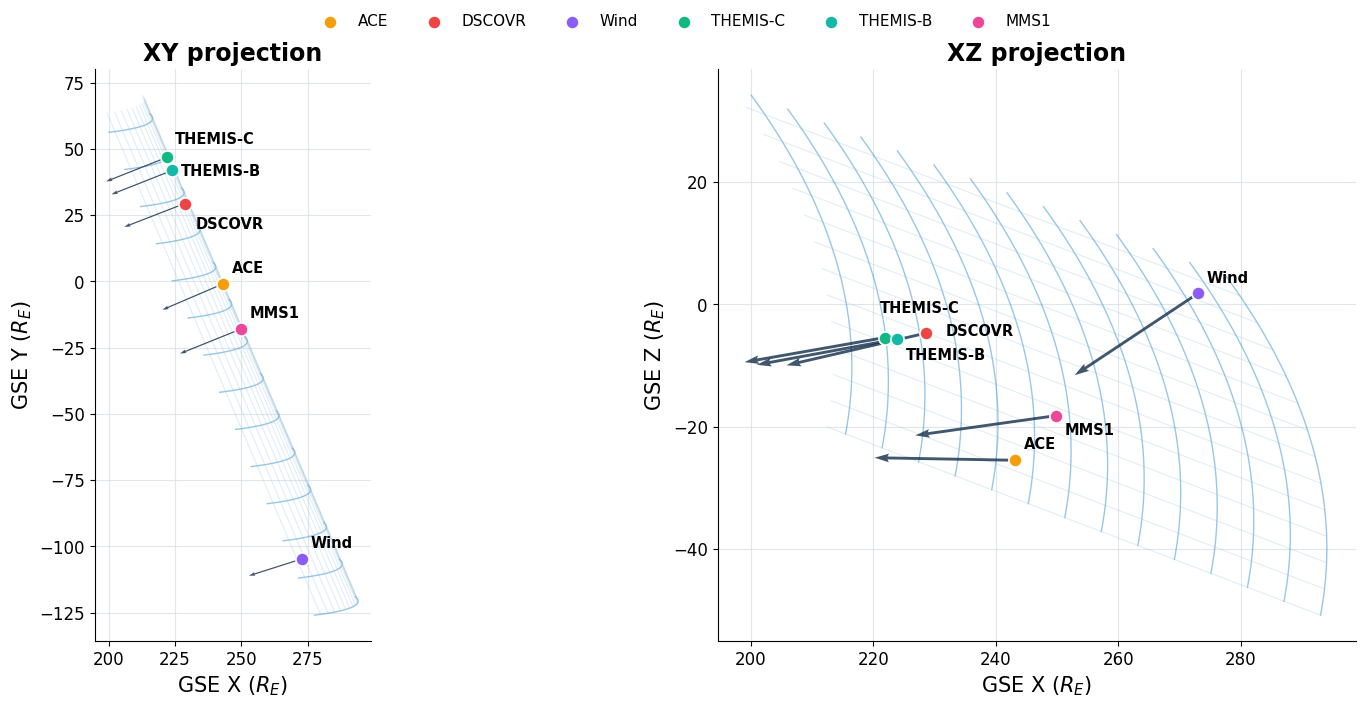

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7), constrained_layout=True)
projection_specs = [((0, 1), "XY projection", "GSE Y ($R_E$)"), ((0, 2), "XZ projection", "GSE Z ($R_E$)")]
normal_length_re = 25.0

for ax, (dimensions, title, vertical_label) in zip(axes, projection_specs):
    horizontal, vertical = dimensions
    for row in range(0, surface.shape[0], 4):
        ax.plot(surface[row, :, horizontal], surface[row, :, vertical], color="#268bd2", lw=1.0, alpha=0.48)
    for column in range(0, surface.shape[1], 7):
        ax.plot(surface[:, column, horizontal], surface[:, column, vertical], color="#8ab8d6", lw=0.8, alpha=0.25)

    ax.quiver(
        co_moving_positions[:, horizontal],
        co_moving_positions[:, vertical],
        normal_length_re * local_normals[:, horizontal],
        normal_length_re * local_normals[:, vertical],
        angles="xy", scale_units="xy", scale=1, width=0.0045,
        color="#17324d", alpha=0.82, zorder=4,
    )
    for satellite, point in zip(satellites, co_moving_positions):
        ax.scatter(
            point[horizontal], point[vertical], s=90,
            color=SATELLITE_COLORS[satellite], edgecolor="white", linewidth=1.2, zorder=5,
            label=SATELLITE_LABELS[satellite],
        )
        ax.annotate(
            SATELLITE_LABELS[satellite], (point[horizontal], point[vertical]),
            xytext=PROJECTION_LABEL_OFFSETS[title][satellite],
            textcoords="offset points", fontsize=10.5, weight="bold",
        )

    ax.set_title(title, weight="bold")
    ax.set_xlabel("GSE X ($R_E$)")
    ax.set_ylabel(vertical_label)
    ax.set_aspect("equal", adjustable="box")
    ax.grid(True, color="#d6dee5", lw=0.8, alpha=0.75)
    ax.spines[["top", "right"]].set_visible(False)

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside upper center", ncol=6, frameon=False)
fig.savefig(PROJECTION_PATH, dpi=220, bbox_inches="tight")
plt.show()

## Three-dimensional common-time surfaces

Both algebraic branches are shown at the ACE crossing epoch. Only a finite segment of each otherwise infinite straight cylinder axis is rendered; this display crop does not alter either fitted surface.

In [10]:
STRAIGHT_AXIS_WIDTH_RE = 150.0
BRANCH_STYLES = {
    1: {"face": "#b7def2", "edge": "#4e96c2", "alpha": 0.42, "wire_alpha": 0.34, "wire_width": 0.45, "marker": "o", "line_style": "-"},
    2: {"face": "#f5b366", "edge": "#c76b12", "alpha": 0.72, "wire_alpha": 0.62, "wire_width": 0.65, "marker": "^", "line_style": "--"},
}

surface_records = []
for branch_number, branch in enumerate(branches, start=1):
    branch_direction = np.asarray(branch["propagationDirectionGSE"], dtype=float)
    branch_speed = float(branch["speedREPerSecond"])
    branch_tilt = np.asarray(branch["tiltVectorGSE"], dtype=float)
    branch_curvature = float(branch["curvatureREInverse"])
    branch_curvature_axis = np.asarray(branch["curvatureAxisGSE"], dtype=float)
    branch_straight_axis = np.cross(branch_direction, branch_curvature_axis)
    branch_straight_axis /= np.linalg.norm(branch_straight_axis)
    branch_offset = float(branch["offsetRE"])

    branch_points = positions - branch_speed * times[:, None] * branch_direction
    branch_relative_positions = branch_points - reference_position
    branch_curved_coordinates = branch_relative_positions @ branch_curvature_axis
    branch_straight_coordinates = branch_relative_positions @ branch_straight_axis

    curved_padding = 0.12 * np.ptp(branch_curved_coordinates)
    curved_values = np.linspace(
        branch_curved_coordinates.min() - curved_padding,
        branch_curved_coordinates.max() + curved_padding,
        90,
    )
    straight_center = 0.5 * (branch_straight_coordinates.min() + branch_straight_coordinates.max())
    straight_values = np.linspace(
        straight_center - STRAIGHT_AXIS_WIDTH_RE / 2,
        straight_center + STRAIGHT_AXIS_WIDTH_RE / 2,
        45,
    )
    branch_curved_grid, branch_straight_grid = np.meshgrid(curved_values, straight_values)
    branch_transverse_grid = (
        branch_curved_grid[..., None] * branch_curvature_axis
        + branch_straight_grid[..., None] * branch_straight_axis
    )
    branch_longitudinal_grid = (
        branch_offset
        + branch_transverse_grid @ branch_tilt
        + 0.5 * branch_curvature * branch_curved_grid**2
    )
    branch_surface = (
        reference_position
        + branch_transverse_grid
        + branch_longitudinal_grid[..., None] * branch_direction
    )
    surface_records.append({
        "branch": branch_number, "surface": branch_surface, "points": branch_points,
        **BRANCH_STYLES[branch_number],
    })

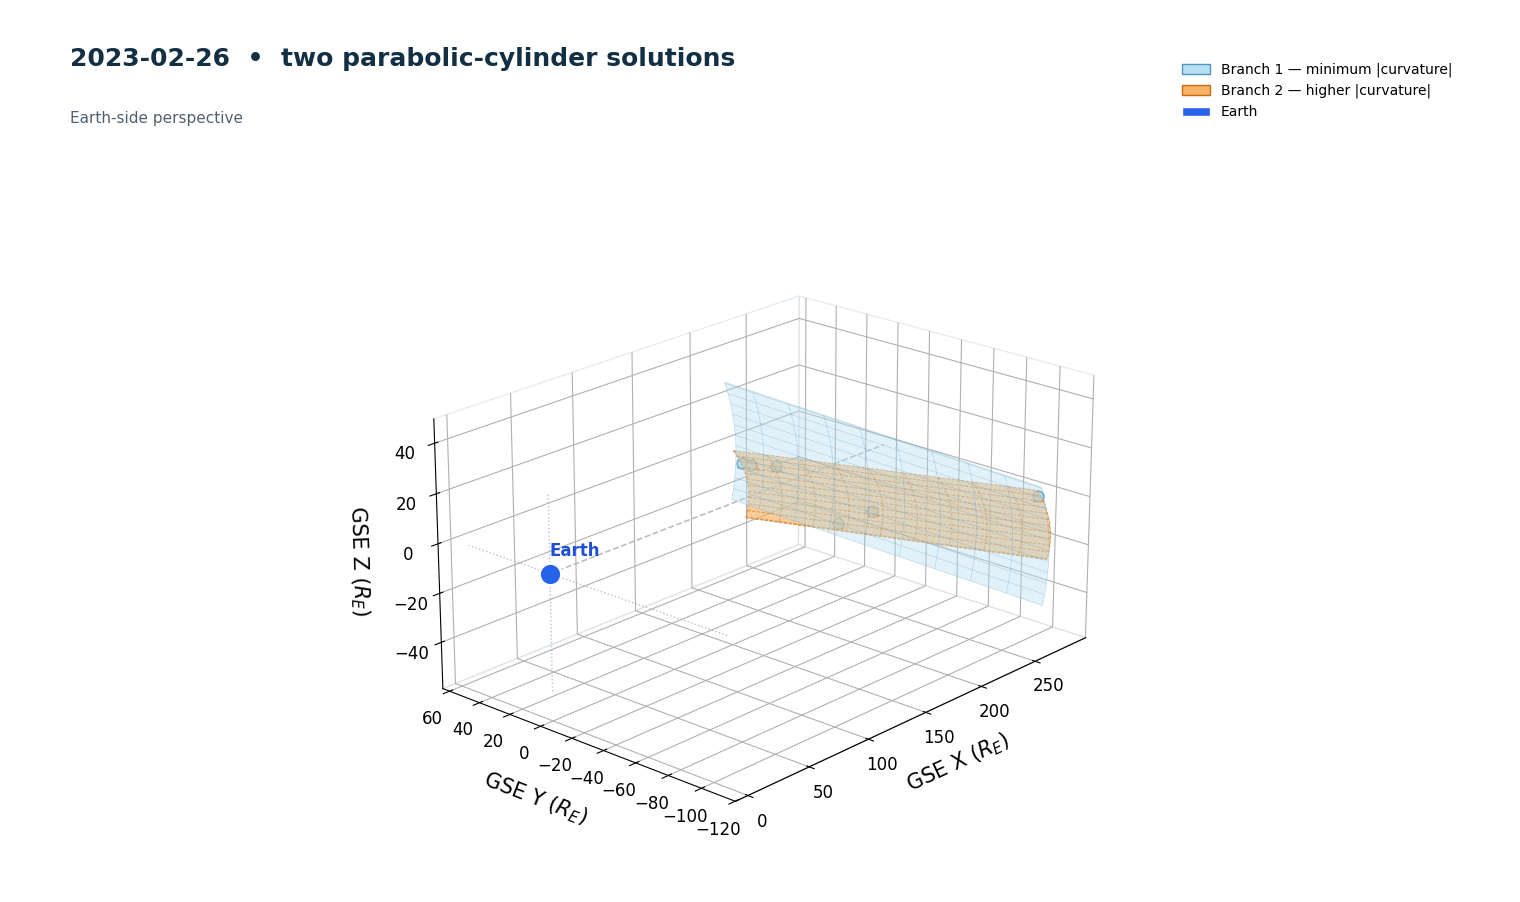

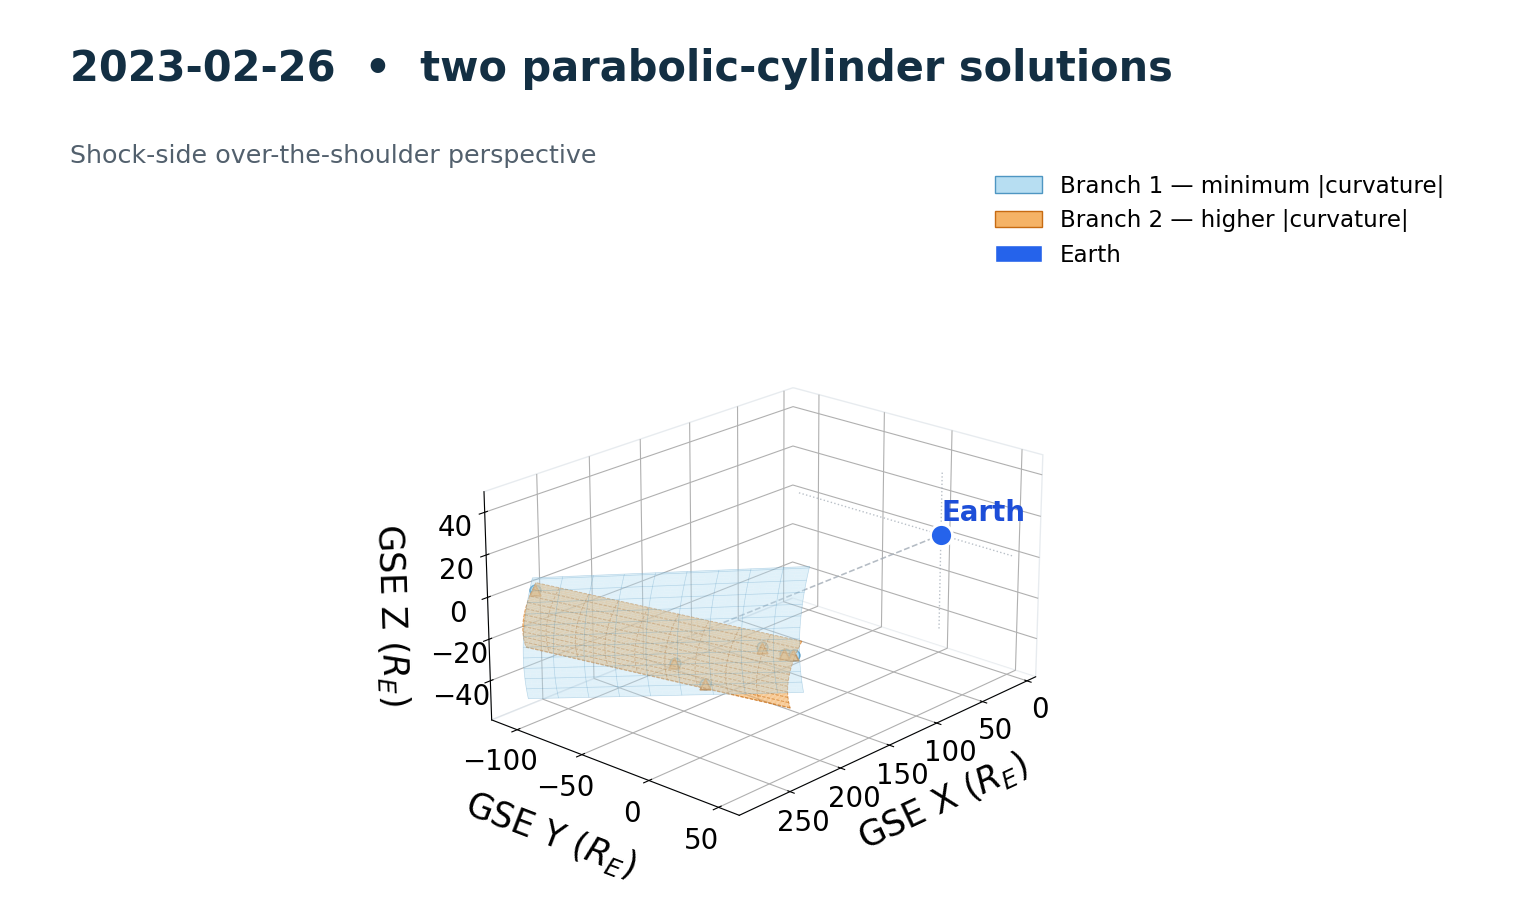

In [11]:
def render_two_branch_view(view_azimuth, view_label, output_path, font_scale=1.0):
    fig = plt.figure(figsize=(15, 9), facecolor="white")
    ax = fig.add_subplot(111, projection="3d", facecolor="white")

    for record in surface_records:
        branch_surface = record["surface"]
        ax.plot_surface(
            branch_surface[..., 0], branch_surface[..., 1], branch_surface[..., 2],
            color=record["face"], linewidth=0, antialiased=True, shade=False, alpha=record["alpha"],
        )
        ax.plot_wireframe(
            branch_surface[..., 0], branch_surface[..., 1], branch_surface[..., 2],
            rstride=5, cstride=8, color=record["edge"], linewidth=record["wire_width"],
            linestyle=record["line_style"], alpha=record["wire_alpha"],
        )
        ax.scatter(
            record["points"][:, 0], record["points"][:, 1], record["points"][:, 2],
            s=58, marker=record["marker"], color=record["face"],
            edgecolor=record["edge"], linewidth=1.15, depthshade=False, zorder=10,
        )

    earth = np.zeros(3)
    all_surfaces = np.concatenate([record["surface"].reshape(-1, 3) for record in surface_records])
    all_x = np.r_[earth[0], all_surfaces[:, 0]]
    all_y = np.r_[earth[1], all_surfaces[:, 1]]
    all_z = np.r_[earth[2], all_surfaces[:, 2]]

    ax.plot([0, all_x.max()], [0, 0], [0, 0], color="#a4adb7", lw=1.15, ls="--", alpha=0.82)
    ax.plot([0, 0], [all_y.min(), all_y.max()], [0, 0], color="#a4adb7", lw=1.0, ls=":", alpha=0.76)
    ax.plot([0, 0], [0, 0], [all_z.min(), all_z.max()], color="#a4adb7", lw=1.0, ls=":", alpha=0.76)
    ax.scatter(*earth, s=250, color="#2563eb", edgecolor="white", linewidth=2.0, depthshade=False, zorder=12)
    ax.text(earth[0], earth[1], earth[2] + 7, "Earth", color="#1d4ed8", fontsize=12 * font_scale, weight="bold")

    ax.set_xlim(all_x.min() - 10, all_x.max() + 12)
    ax.set_ylim(all_y.min() - 12, all_y.max() + 12)
    ax.set_zlim(all_z.min() - 12, all_z.max() + 18)
    ax.set_box_aspect((1.35, 1.0, 0.72))
    ax.view_init(elev=21, azim=view_azimuth)
    ax.set_xlabel("GSE X ($R_E$)", fontsize=15 * font_scale, labelpad=12 * font_scale)
    ax.set_ylabel("GSE Y ($R_E$)", fontsize=15 * font_scale, labelpad=12 * font_scale)
    ax.set_zlabel("GSE Z ($R_E$)", fontsize=15 * font_scale, labelpad=10 * font_scale)
    ax.tick_params(axis="both", which="major", labelsize=12 * font_scale)
    ax.zaxis.set_tick_params(labelsize=12 * font_scale)
    legend_handles = [
        Patch(facecolor=BRANCH_STYLES[1]["face"], edgecolor=BRANCH_STYLES[1]["edge"], label="Branch 1 — minimum |curvature|"),
        Patch(facecolor=BRANCH_STYLES[2]["face"], edgecolor=BRANCH_STYLES[2]["edge"], label="Branch 2 — higher |curvature|"),
        Patch(facecolor="#2563eb", edgecolor="white", label="Earth"),
    ]
    header_height = 0.30 if font_scale > 1.0 else 0.18
    header_title_y = 0.78 if font_scale > 1.0 else 0.70
    header_subtitle_y = 0.46 if font_scale > 1.0 else 0.33
    header_legend_y = 0.22 if font_scale > 1.0 else 0.50
    header_ax = fig.add_axes([0.0, 1.0 - header_height, 1.0, header_height], facecolor="white", zorder=1000)
    header_ax.set_axis_off()
    header_ax.text(
        0.04, header_title_y, "2023-02-26  •  two parabolic-cylinder solutions",
        fontsize=18 * font_scale, weight="bold", color="#132f43", va="center",
    )
    header_ax.text(0.04, header_subtitle_y, view_label, fontsize=11 * font_scale, color="#52606d", va="center")
    header_ax.legend(handles=legend_handles, loc="center right", bbox_to_anchor=(0.97, header_legend_y), frameon=False, fontsize=10 * font_scale)
    ax.grid(True, color="#d6dbe1", alpha=0.75)
    for axis in (ax.xaxis, ax.yaxis, ax.zaxis):
        axis.pane.set_facecolor((1.0, 1.0, 1.0, 1.0))
        axis.pane.set_edgecolor((0.82, 0.85, 0.88, 1.0))

    ax.set_position([0.02, 0.02, 0.96, 1.0 - header_height - 0.04])
    fig.savefig(output_path, dpi=240, facecolor="white")
    plt.show()


render_two_branch_view(-138, "Earth-side perspective", VIEW_3D_PATH)
render_two_branch_view(42, "Shock-side over-the-shoulder perspective", VIEW_3D_SHOCK_PATH, font_scale=1.66)

## Result

The six crossings exactly constrain two positive real cylindrical branches. Both pass all four available shock-faster-than-downstream comparisons, so this kinematic test does not distinguish the physical branch. The three-dimensional view therefore shows both roots without selecting one.